In [5]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Dataset
--

In [6]:
df1 = pd.read_csv("C:\\Users\\SAMPADA\\Downloads\\project\\inventory_discrepancy_log_large.csv")
df2 = pd.read_csv("C:\\Users\\SAMPADA\\Downloads\\project\\inventory_item_master_large.csv")
df3 = pd.read_csv("C:\\Users\\SAMPADA\\Downloads\\project\\inventory_kpi_summary_large.csv")
df4 = pd.read_csv("C:\\Users\\SAMPADA\\Downloads\\project\\inventory_movement_log_large.csv")
df5 = pd.read_csv("C:\\Users\\SAMPADA\\Downloads\\project\\inventory_profiling_large.csv")
df6 = pd.read_csv(r"C:\Users\SAMPADA\Downloads\project\inventory_validation_log_large.csv")
df7 = pd.read_csv(r"C:\Users\SAMPADA\Downloads\project\task_allocation_log_large.csv")

Information Of Dataset
--

In [7]:
# Example: suppose you have multiple DataFrames in a dictionary
datasets = {
    "inventory_discrepancy_log_large": df1,
    "inventory_item_master_large": df2,
    "inventory_kpi_summary_large": df3,
    "inventory_movement_log_large": df4,
    "inventory_profiling_large": df5,
    "inventory_validation_log_large": df6,
    "task_allocation_log_large": df7
}

def dataset_summary(df, name):
    print(f"--- Summary for {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:\n", df.isnull().sum())
    print("Duplicated rows:", df.duplicated().sum())
    print("\nInfo:")
    print(df.info())
    print("-"*50, "\n")

# Loop through all datasets
for name, df in datasets.items():
    dataset_summary(df, name)

--- Summary for inventory_discrepancy_log_large ---
Shape: (15336, 11)
Columns: ['Discrepancy_ID', 'Movement_ID', 'Item_ID', 'Warehouse_Code', 'Discrepancy_Date', 'Expected_Quantity', 'Actual_Quantity', 'Variance_Quantity', 'Discrepancy_Type', 'Root_Cause', 'Resolution_Status']
Missing values:
 Discrepancy_ID       0
Movement_ID          0
Item_ID              0
Warehouse_Code       0
Discrepancy_Date     0
Expected_Quantity    0
Actual_Quantity      0
Variance_Quantity    0
Discrepancy_Type     0
Root_Cause           0
Resolution_Status    0
dtype: int64
Duplicated rows: 0

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15336 entries, 0 to 15335
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Discrepancy_ID     15336 non-null  object
 1   Movement_ID        15336 non-null  object
 2   Item_ID            15336 non-null  object
 3   Warehouse_Code     15336 non-null  object
 4   Discrepancy_Date

seperate categorical, numerical and datetime column
--

In [13]:
df['Discrepancy_Date']= pd.to_datetime(df['Discrepancy_Date'])

In [14]:
# Numerical columns (int, float)
numerical_df = df.select_dtypes(include=["int64", "float64"])

# Categorical columns (object, category)
categorical_df = df.select_dtypes(include=["object", "category"])

# DataTime columns (datatime64[ns])
date_df = df.select_dtypes(include=["datetime64[ns]"])

data cleaning
--
a. check missing values and duplicate
--

In [15]:
df.isnull().mean()*100

Discrepancy_ID       0.0
Movement_ID          0.0
Item_ID              0.0
Warehouse_Code       0.0
Discrepancy_Date     0.0
Expected_Quantity    0.0
Actual_Quantity      0.0
Variance_Quantity    0.0
Discrepancy_Type     0.0
Root_Cause           0.0
Resolution_Status    0.0
dtype: float64

In [16]:
df.duplicated().mean()

np.float64(0.0)

Statistics 
--

In [17]:
df.describe()

,Discrepancy_Date,Expected_Quantity,Actual_Quantity,Variance_Quantity
count,15336,15336.000000,15336.000000,15336.000000
mean,2022-12-24 09:05:15.492957696,19.230112,18.904604,-0.325509
min,2021-01-01 00:00:00,1.000000,0.000000,-10.000000
25%,2021-12-25 00:00:00,12.000000,10.000000,-5.000000
50%,2022-12-16 00:00:00,18.000000,18.000000,0.000000
75%,2023-12-20 00:00:00,26.000000,26.000000,5.000000
max,2024-12-31 00:00:00,55.000000,61.000000,9.000000
std,NaN,10.057879,11.286313,5.656388


In [20]:
# Remove ID columns
categorical_df = [col for col in categorical_df if 'id' not in col.lower()]
for col in categorical_df:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Column: Warehouse_Code
Warehouse_Code
WH_BLR_01    2652
WH_CHN_01    2598
WH_NAG_01    2560
WH_DEL_01    2553
WH_MUM_01    2504
WH_PUN_01    2469
Name: count, dtype: int64

Column: Discrepancy_Type
Discrepancy_Type
Damage         3135
Excess         3085
Shortage       3059
Count Error    3056
Wrong Item     3001
Name: count, dtype: int64

Column: Root_Cause
Root_Cause
System posting delay     2621
Manual counting error    2589
Wrong bin placement      2562
Vendor short supply      2556
Handling damage          2548
Documentation missing    2460
Name: count, dtype: int64

Column: Resolution_Status
Resolution_Status
Resolved               4592
Under Investigation    3883
Open                   3793
Adjusted               3068
Name: count, dtype: int64


Exploratory Data Analysis (EDA) 
--
multivariate analysis 
--

<Axes: xlabel='Expected_Quantity', ylabel='Actual_Quantity'>

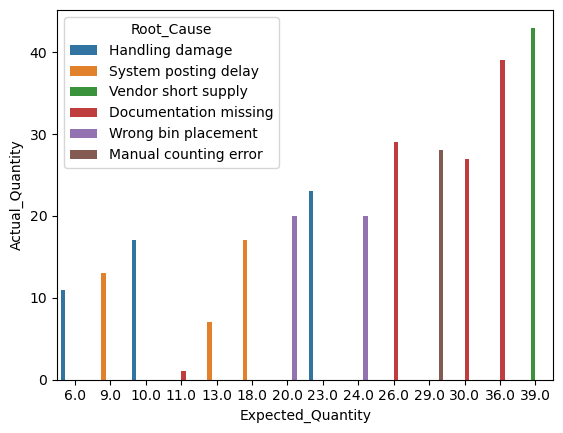

In [16]:
sns.barplot(x=df1['Expected_Quantity'].head(15),y=df1['Actual_Quantity'].head(15),hue=df1['Root_Cause'])

dataset: 3
--
seperate the column such as categorical, numerical and datetime
--

In [11]:
df3['Year_Month'] = pd.to_datetime(df3['Year_Month'])

In [12]:
#Numerical columns (int, float)
numerical_col = df3.select_dtypes(include=["int64", "float64"])

#Categorical columns (Object)
categorical_col = df3.select_dtypes(include=["object"])

#DataTime columns (datatime64[ns])
date_col = df3.select_dtypes(include=["datetime64[ns]"])

statistics
--

In [13]:
df3.describe()

,Year_Month,Tasks_Assigned,Tasks_Completed,Avg_Assigned_Qty,Total_Movements,Inward_Movements,Outward_Movements,Total_Quantity_Moved,Mismatch_Count,Discrepancy_Count,Total_Variance,Validations_Done,Validation_Failures,Task_Completion_Rate_%,Mismatch_Rate_%,Validation_Failure_Rate_%
count,288,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000
mean,2022-12-16 05:00:00,347.222222,294.781250,20.153749,416.666667,200.270833,216.395833,8171.125000,42.031250,53.250000,-17.333333,428.416667,93.666667,84.889514,10.088194,21.885417
min,2021-01-01 00:00:00,282.000000,236.000000,18.617089,340.000000,157.000000,163.000000,6623.000000,26.000000,37.000000,-133.000000,365.000000,70.000000,78.270000,6.580000,16.510000
25%,2021-12-24 06:00:00,333.000000,282.000000,19.797077,400.750000,189.000000,205.000000,7832.750000,38.000000,48.000000,-41.000000,410.750000,87.000000,83.475000,9.110000,20.420000
50%,2022-12-16 12:00:00,349.000000,296.000000,20.154214,417.000000,201.000000,216.000000,8169.500000,42.000000,53.000000,-18.000000,432.000000,93.000000,84.980000,10.040000,21.860000
75%,2023-12-08 18:00:00,362.000000,310.000000,20.549882,434.000000,211.000000,226.000000,8525.250000,46.000000,58.000000,8.250000,443.500000,101.250000,86.327500,11.002500,23.242500
max,2024-12-01 00:00:00,405.000000,347.000000,21.439891,491.000000,236.000000,274.000000,9729.000000,64.000000,78.000000,139.000000,476.000000,114.000000,89.520000,15.060000,25.470000
std,NaN,21.271415,19.684906,0.531828,24.940906,15.201191,16.719335,526.715414,6.493288,7.435671,40.018898,25.395684,9.669810,1.954965,1.445138,2.081505


In [14]:
for col in categorical_col:
    print(f"\nColumn: {col}")
    print(df3[col].value_counts(dropna=False))


Column: Warehouse_Code
Warehouse_Code
WH_BLR_01    48
WH_CHN_01    48
WH_DEL_01    48
WH_MUM_01    48
WH_NAG_01    48
WH_PUN_01    48
Name: count, dtype: int64


Multivariate analysis 
--

<Axes: xlabel='Mismatch_Count', ylabel='Discrepancy_Count'>

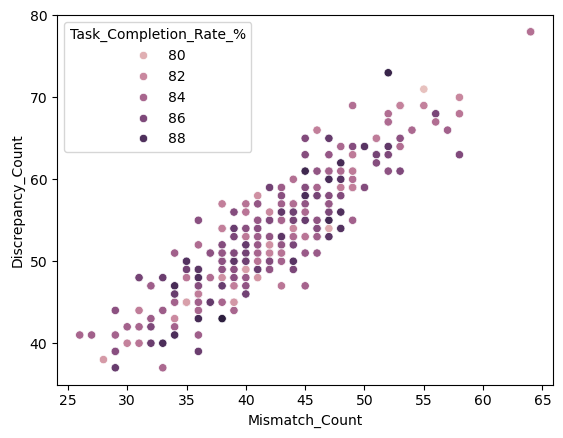

In [15]:
sns.scatterplot(x=df3['Mismatch_Count'],y=df3['Discrepancy_Count'], hue=df3['Task_Completion_Rate_%'])

dataset: 4
--
seperate datetime , categorical as well as numerical columns
--

In [17]:
df4['Movement_Date'] = pd.to_datetime(df4['Movement_Date'])

In [18]:
#categorical column(object)
categorical_df4 = df4.select_dtypes(include=["object"])

#numerical column(int,float)
numerical_df4 = df4.select_dtypes(include=["int64","float64"])

#date column(datetime64[ns])
date_df4 = df4.select_dtypes(include=["datetime64[ns]"])

statistics
--

In [19]:
df4.describe()

,Movement_Date,Movement_Quantity
count,120000,120000.000000
mean,2022-12-30 21:10:23.520000256,19.610700
min,2021-01-01 00:00:00,1.000000
25%,2022-01-01 00:00:00,13.000000
50%,2022-12-27 00:00:00,19.000000
75%,2023-12-30 00:00:00,26.000000
max,2024-12-31 00:00:00,55.000000
std,NaN,9.975875


In [20]:
# Remove ID columns
categorical_df4 = [col for col in categorical_df4 if 'id' not in col.lower()]
for col in categorical_df4:
    print(f"\nColumn: {col}")
    print(df4[col].value_counts(dropna=False))


Column: Warehouse_Code
Warehouse_Code
WH_BLR_01    20335
WH_NAG_01    20134
WH_MUM_01    20052
WH_DEL_01    19993
WH_CHN_01    19788
WH_PUN_01    19698
Name: count, dtype: int64

Column: Movement_Type
Movement_Type
Outward    62322
Inward     57678
Name: count, dtype: int64

Column: Source
Source
Return    40116
Plant     40030
Vendor    39854
Name: count, dtype: int64

Column: Destination
Destination
Plant                 40083
Customer              40058
Warehouse Transfer    39859
Name: count, dtype: int64

Column: Verification_Status
Verification_Status
Verified    101899
Mismatch     12105
Pending       5996
Name: count, dtype: int64


Exploratory Data Analysis (EDA)
--
multivariate analysis
--

<Axes: xlabel='Source', ylabel='Destination'>

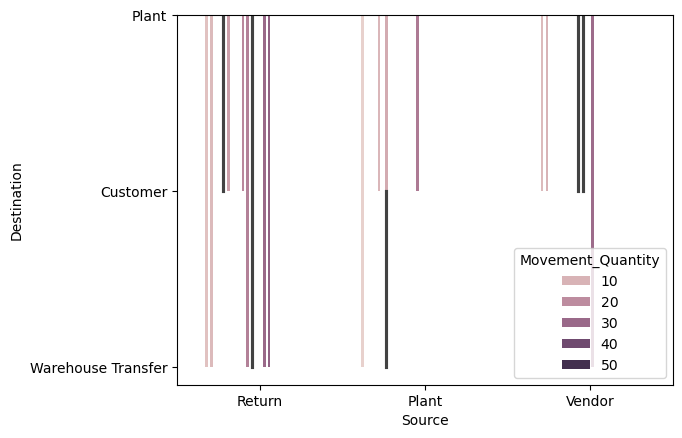

In [23]:
sns.barplot(x=df4['Source'].head(30),y=df4['Destination'].head(30),hue=df4['Movement_Quantity'])

dataset: 7 
--

seperate categorical, numerical and datetime columns
--

In [24]:
df7['Task_Date'] = pd.to_datetime(df7['Task_Date'])

In [25]:
# Numerical columns (int, float)
numerical_df7 = df7.select_dtypes(include=["int64", "float64"])

# Categorical columns (object)
categorical_df7 = df7.select_dtypes(include=["object"])

# DataTime columns (datatime64[ns])
date_df7 = df7.select_dtypes(include=["datetime64[ns]"])

statistics
--

In [26]:
df7.describe()

,Task_Date,Assigned_Quantity
count,100000,100000.000000
mean,2022-12-31 09:43:51.744000,20.151760
min,2021-01-01 00:00:00,1.000000
25%,2021-12-30 00:00:00,13.000000
50%,2023-01-01 00:00:00,19.000000
75%,2023-12-30 06:00:00,27.000000
max,2024-12-31 00:00:00,48.000000
std,NaN,9.822401


In [27]:
# Remove ID columns
categorical_df7 = [col for col in categorical_df7 if 'id' not in col.lower()]
for col in categorical_df7:
    print(f"\nColumn: {col}")
    print(df7[col].value_counts(dropna=False))


Column: Warehouse_Code
Warehouse_Code
WH_NAG_01    16826
WH_BLR_01    16821
WH_MUM_01    16706
WH_CHN_01    16631
WH_DEL_01    16619
WH_PUN_01    16397
Name: count, dtype: int64

Column: Task_Type
Task_Type
Picking                 14518
Putaway                 14412
Outbound Dispatch       14305
Inbound Verification    14267
Cycle Count             14243
Stock Transfer          14170
Packing                 14085
Name: count, dtype: int64

Column: Assigned_Staff
Assigned_Staff
staff_ajay     17944
staff_rohit    15050
staff_sneha    14004
staff_priya    12107
staff_amit     12006
staff_kiran     9991
staff_sonal     9946
staff_vikas     8952
Name: count, dtype: int64

Column: Task_Status
Task_Status
Completed    84897
Pending      10011
Cancelled     5092
Name: count, dtype: int64


Exploratory Data Analysis (EDA)
--
multivariate analysis
--

<Axes: xlabel='Task_Type', ylabel='Task_Status'>

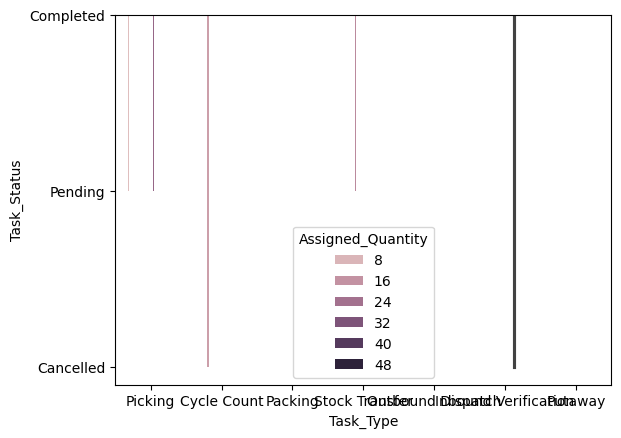

In [23]:
sns.barplot(x=df7['Task_Type'].head(30),y=df7['Task_Status'].head(30),hue=df7['Assigned_Quantity'])